# Predicting Corporate Bond Returns for Next Month

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Problem Statement/Business Problem

In [ ]:
Fund managers usually find out a bond is in trouble only after its price has already dropped by a downgrade, 
bad news, or a market reaction that's already happened. By then, it's too late to avoid the loss, and the fund often ends up 
selling at a bad price simply because everyone else is selling too. What's missing is an early, trustworthy signal that says 
"this bond looks risky for next month" — while there's still time to act, 
instead of finding out after the damage is done.

In [3]:
df = pd.read_csv('bond_data.csv')

In [4]:
df

,bond_id,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,company_size,market_fear_level,inflation_rate,next_month_return_pct
0,BND2507,01-01-2021,2.813,13.0,36.569,10.77,6.665,0.3561,-0.2700,0.7939,-1.2909,9.483,9.00,2.90,-0.3763
1,BND2818,01-09-2021,1.909,9.0,17.181,1.01,4.977,-0.3054,-0.1745,-0.1747,-1.2254,7.267,20.31,3.80,-1.4180
2,BND2452,01-07-2018,2.991,11.0,32.901,6.53,5.554,1.4426,-0.1698,0.8600,0.3770,9.367,26.58,4.88,-0.1122
3,BND2368,01-08-2018,7.324,15.0,109.860,5.86,11.427,-0.2411,-0.6162,0.9306,0.2764,10.829,15.74,1.57,-1.1309
4,BND2242,01-10-2019,2.756,12.0,33.072,5.34,5.093,-0.7371,-1.7149,0.1911,-0.5198,7.820,9.00,NaN,-0.2815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,BND2767,01-11-2018,1.499,8.0,11.992,1.18,3.464,0.3952,0.2798,0.5498,1.8701,NaN,17.89,NaN,-0.3672
996,BND2072,01-06-2021,2.364,9.0,21.276,8.61,4.417,-0.6762,-1.0482,0.7971,-1.1192,9.403,9.00,3.79,-0.3518
997,BND2908,01-09-2020,1.121,6.0,6.726,10.46,3.365,-0.3406,0.2867,0.6854,0.8865,10.045,17.13,0.82,0.2241
998,BND2235,01-09-2021,3.942,11.0,43.362,10.37,5.467,-0.8407,0.8399,0.3718,0.2227,8.181,33.74,1.55,-0.7766


In [5]:
df.head(10)

,bond_id,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,company_size,market_fear_level,inflation_rate,next_month_return_pct
0,BND2507,01-01-2021,2.813,13.0,36.569,10.77,6.665,0.3561,-0.2700,0.7939,-1.2909,9.483,9.00,2.90,-0.3763
1,BND2818,01-09-2021,1.909,9.0,17.181,1.01,4.977,-0.3054,-0.1745,-0.1747,-1.2254,7.267,20.31,3.80,-1.4180
2,BND2452,01-07-2018,2.991,11.0,32.901,6.53,5.554,1.4426,-0.1698,0.8600,0.3770,9.367,26.58,4.88,-0.1122
3,BND2368,01-08-2018,7.324,15.0,109.860,5.86,11.427,-0.2411,-0.6162,0.9306,0.2764,10.829,15.74,1.57,-1.1309
4,BND2242,01-10-2019,2.756,12.0,33.072,5.34,5.093,-0.7371,-1.7149,0.1911,-0.5198,7.820,9.00,NaN,-0.2815
5,BND2929,01-06-2019,3.685,15.0,55.275,8.56,5.687,0.9626,0.8428,-0.6423,1.0527,8.668,14.61,4.51,0.4520
6,BND2262,01-01-2021,4.071,10.0,40.710,12.61,7.225,0.6554,0.0557,-0.9072,0.2072,8.592,23.37,3.85,0.2773
7,BND2810,01-06-2017,2.290,11.0,25.190,8.39,6.399,0.9760,-0.2730,1.5349,-0.3837,6.890,16.27,2.18,-1.1394
8,BND2318,01-01-2019,2.016,5.0,10.080,5.46,4.654,-1.4482,-0.5108,-1.2146,1.2168,9.160,31.85,2.12,-0.1741
9,BND2049,01-05-2021,3.095,10.0,30.950,6.32,4.926,0.6665,-0.2395,-0.1077,-0.1490,8.170,9.00,3.51,-0.2882


# EDA Steps

### 1. Check DataShape 

In [6]:
df.shape

(1000, 15)

### 2. Check DataType

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   bond_id                    1000 non-null   str    
 1   obs_date                   1000 non-null   str    
 2   extra_interest_offered     1000 non-null   float64
 3   credit_rating_score        1000 non-null   float64
 4   overall_risk_score         1000 non-null   float64
 5   maturity_period_years      1000 non-null   float64
 6   total_return_rate          1000 non-null   float64
 7   interest_rate_trend        1000 non-null   float64
 8   economic_condition_change  1000 non-null   float64
 9   market_sentiment_change    1000 non-null   float64
 10  recent_performance_trend   1000 non-null   float64
 11  company_size               950 non-null    float64
 12  market_fear_level          1000 non-null   float64
 13  inflation_rate             940 non-null    float64
 14  next

### 3. Statistical Summary

In [8]:
df.describe()

,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,company_size,market_fear_level,inflation_rate,next_month_return_pct
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,950.000000,1000.000000,940.000000,1000.000000
mean,2.744075,10.963000,34.828549,6.589400,5.988134,-0.006661,0.009540,0.067291,0.004558,8.473546,18.589280,2.779457,-0.290323
std,1.646899,3.511689,33.173279,2.784796,5.977496,0.973493,0.881745,0.982344,1.110514,1.292178,8.517514,1.381796,0.784910
min,0.349000,1.000000,0.711000,0.500000,1.788000,-2.666400,-3.106600,-2.949300,-3.315100,4.000000,9.000000,-1.000000,-4.002000
25%,1.502000,8.750000,12.908250,4.557500,3.979000,-0.674850,-0.555725,-0.606750,-0.786525,7.609250,11.787500,1.840000,-0.772050
50%,2.396000,11.000000,24.376500,6.500000,4.988500,-0.000950,0.013500,0.099350,-0.009650,8.449500,16.525000,2.810000,-0.254550
75%,3.564000,13.000000,44.194500,8.532500,6.304000,0.656375,0.610775,0.736475,0.803250,9.389750,23.355000,3.782500,0.232325
max,11.951000,22.000000,262.922000,16.480000,58.759000,3.175300,2.803000,2.675600,3.544000,12.258000,55.690000,6.840000,2.521700


In [9]:
f = df.describe() 
f.shape

(8, 13)

### 4. Check Missing Values

In [10]:
df.isnull().sum()

bond_id                       0
obs_date                      0
extra_interest_offered        0
credit_rating_score           0
overall_risk_score            0
maturity_period_years         0
total_return_rate             0
interest_rate_trend           0
economic_condition_change     0
market_sentiment_change       0
recent_performance_trend      0
company_size                 50
market_fear_level             0
inflation_rate               60
next_month_return_pct         0
dtype: int64

# 5. Checking Each Column Graph

### 5.1 extra_interest_offered

In [11]:
df['extra_interest_offered'].unique()

array([ 2.813,  1.909,  2.991,  7.324,  2.756,  3.685,  4.071,  2.29 ,
        2.016,  3.095,  0.995,  4.648,  7.208,  1.141,  1.981,  1.274,
        1.422,  3.727,  2.011,  6.464,  3.446,  2.253,  5.447,  4.938,
        2.954,  2.426,  2.123,  2.755,  0.78 ,  1.844,  1.807,  1.648,
        1.508,  2.841,  4.601,  1.355,  3.405,  0.535,  1.842,  3.044,
        2.007,  5.14 ,  1.442,  1.248,  1.024,  1.015,  1.259,  2.757,
        2.205,  1.88 ,  6.676,  4.735,  1.24 ,  2.339,  5.383,  2.593,
        5.04 ,  4.495,  1.758,  3.205,  1.574,  7.254,  3.075,  6.509,
        3.359,  5.022,  1.365,  1.924,  1.541,  4.27 ,  2.297,  2.06 ,
        0.782,  0.857,  5.142,  1.595,  1.799,  3.028,  1.139,  2.354,
        2.407,  2.176,  2.325,  2.324,  1.496,  3.133,  3.286,  2.468,
        1.256,  1.453,  4.359,  0.848,  5.751,  3.187,  4.501,  2.179,
        3.909,  3.099,  2.161,  0.698,  1.824,  3.305,  1.131,  1.941,
        0.986,  4.271,  1.75 ,  8.593,  3.798,  3.766,  1.989,  1.956,
      

In [12]:
df['extra_interest_offered'].nunique()

905

In [13]:
df['extra_interest_offered'].duplicated().sum()

np.int64(95)

<Axes: xlabel='extra_interest_offered', ylabel='Count'>

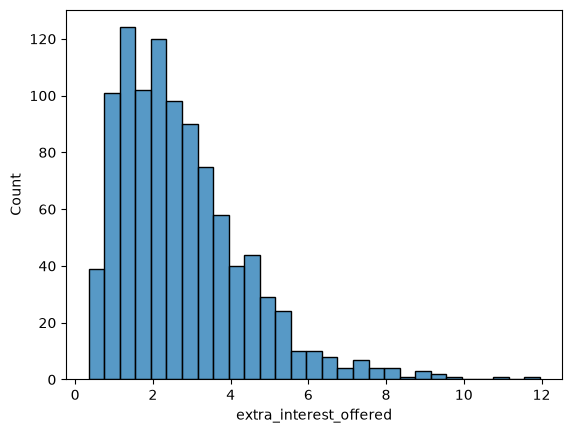

In [14]:
sns.histplot(df['extra_interest_offered'])

<Axes: xlabel='extra_interest_offered', ylabel='Density'>

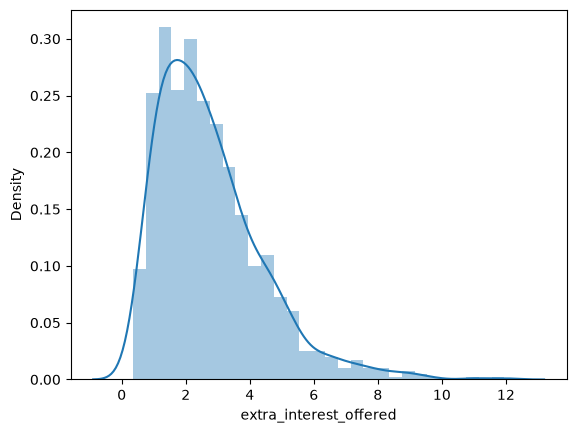

In [15]:
sns.distplot(df['extra_interest_offered'])

<Axes: xlabel='extra_interest_offered', ylabel='Density'>

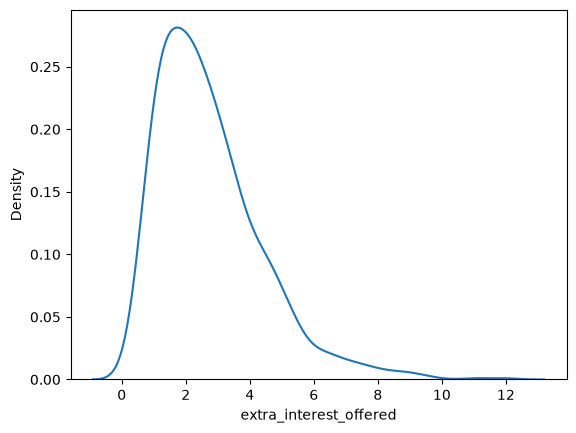

In [16]:
sns.kdeplot(df['extra_interest_offered'])

<Axes: xlabel='extra_interest_offered', ylabel='count'>

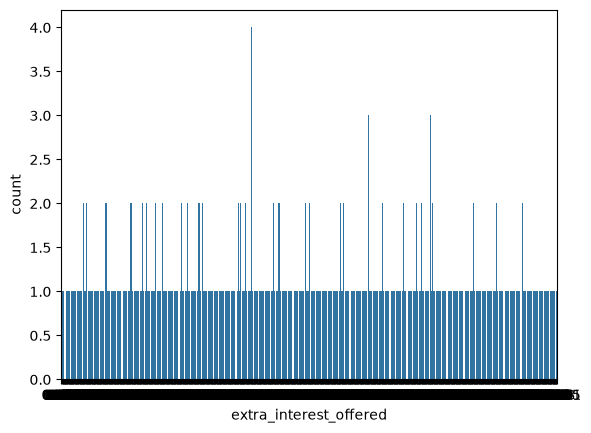

In [17]:
sns.countplot(x=df['extra_interest_offered'])

<Axes: ylabel='extra_interest_offered'>

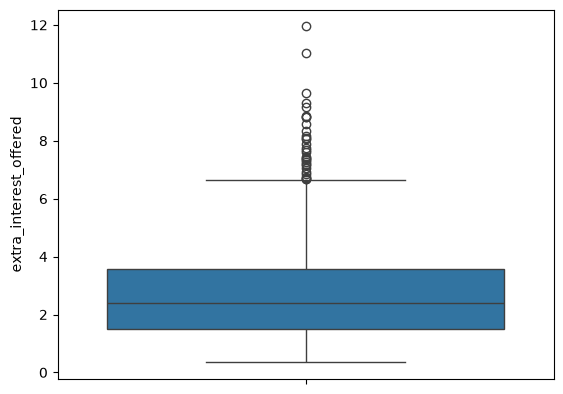

In [18]:
sns.boxplot(df['extra_interest_offered'])

In [19]:
df['extra_interest_offered'].skew()

np.float64(1.366137894761227)

### 5.2 - credit_rating_score

In [20]:
df['credit_rating_score'].unique()

array([13.,  9., 11., 15., 12., 10.,  5., 18.,  7., 19., 17., 14.,  8.,
        6., 21., 16.,  4., 20., 22.,  3.,  2.,  1.])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

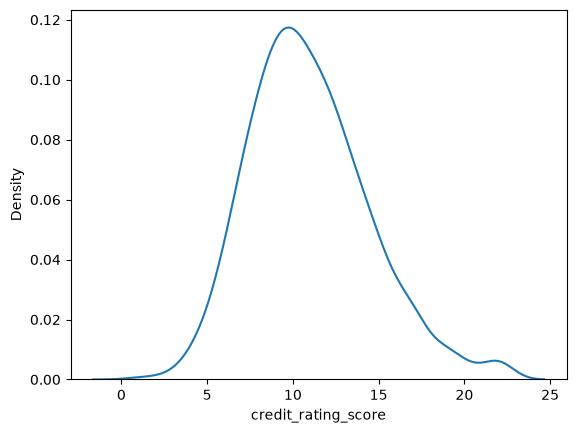

In [21]:
sns.kdeplot(df['credit_rating_score'])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

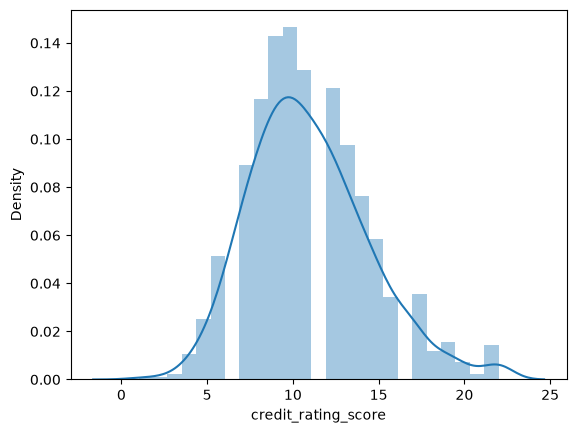

In [22]:
sns.distplot(df['credit_rating_score'])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

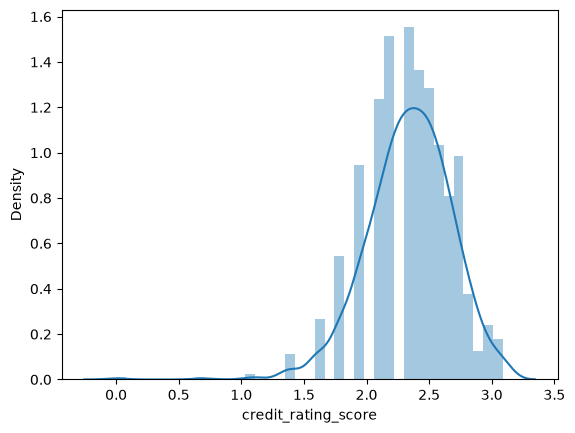

In [23]:
sns.distplot(np.log(df['credit_rating_score']))

<Axes: ylabel='credit_rating_score'>

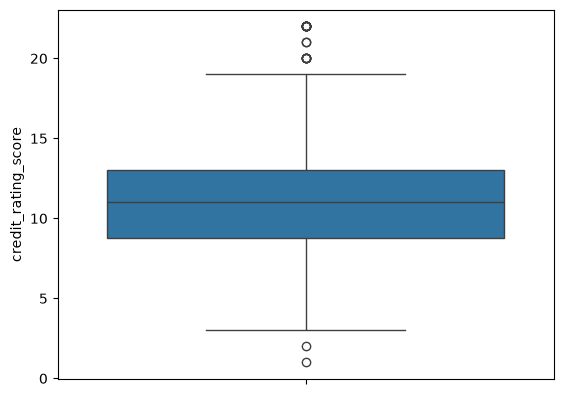

In [24]:
sns.boxplot(df['credit_rating_score'])

In [29]:
df['credit_rating_score'].skew()

np.float64(0.5847326477422036)

In [30]:
df['credit_rating_score'].unique()

array([13.,  9., 11., 15., 12., 10.,  5., 18.,  7., 19., 17., 14.,  8.,
        6., 21., 16.,  4., 20., 22.,  3.,  2.,  1.])

In [31]:
df['credit_rating_score'].nunique()

22

In [32]:
df['credit_rating_score'].duplicated().sum()

np.int64(978)

### 5.3 overall_risk_score

In [33]:
df['overall_risk_score'].unique()

array([ 36.569,  17.181,  32.901, 109.86 ,  33.072,  55.275,  40.71 ,
        25.19 ,  10.08 ,  30.95 ,   8.955,  69.72 , 129.744,  11.41 ,
        17.829,   6.37 ,   9.954,  40.997,  22.121,  96.96 ,  44.798,
        27.036, 103.493,  83.946,  41.356,  26.686,  21.23 ,  27.55 ,
         8.58 ,  14.752,  14.456,  18.128,  12.064,  31.251,  64.414,
        10.84 ,  37.455,   3.745,  23.946,  30.44 ,  18.063,  87.38 ,
        12.978,   9.984,   9.216,   6.09 ,   7.554,  27.57 ,  22.05 ,
        22.56 , 140.196,  80.495,   8.68 ,  23.39 ,  86.128,  25.93 ,
        80.64 ,  58.435,  19.338,  38.46 ,  12.592, 137.826,  39.975,
        97.635,  43.667,  75.33 ,   9.555,  19.24 ,  16.951,  64.05 ,
        18.376,  26.78 ,   5.474,   7.713,   3.128,  71.988,  11.165,
        17.99 ,  24.224,   9.112,  18.832,  31.291,  23.936,  27.9  ,
        23.24 ,  13.464,  40.729,  39.432,  32.084,  11.304,  11.624,
        56.667,   5.088,  97.767,  28.683,  72.016,  23.969,  50.817,
        37.188,  23.

<Axes: xlabel='overall_risk_score', ylabel='Density'>

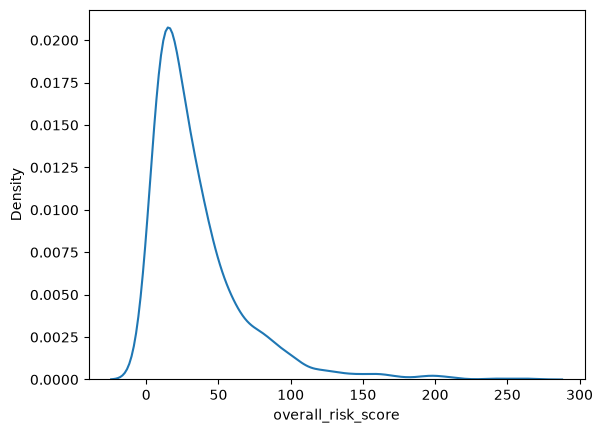

In [34]:
sns.kdeplot(df['overall_risk_score'])

<Axes: xlabel='overall_risk_score', ylabel='Density'>

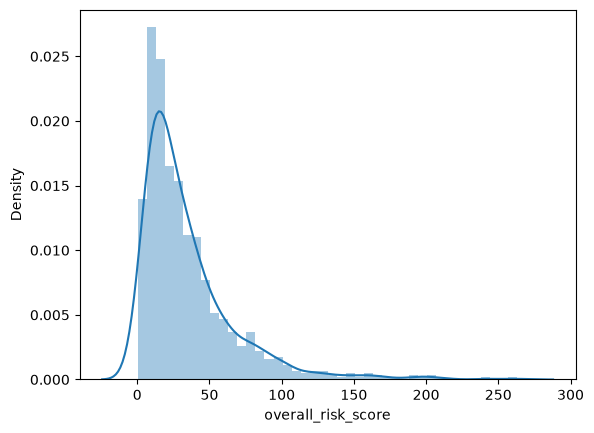

In [35]:
sns.distplot(df['overall_risk_score'])

<Axes: xlabel='overall_risk_score', ylabel='Density'>

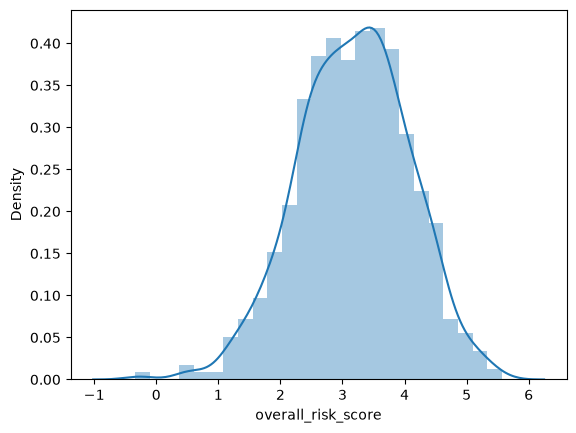

In [36]:
sns.distplot(np.log(df['overall_risk_score']))

<Axes: ylabel='overall_risk_score'>

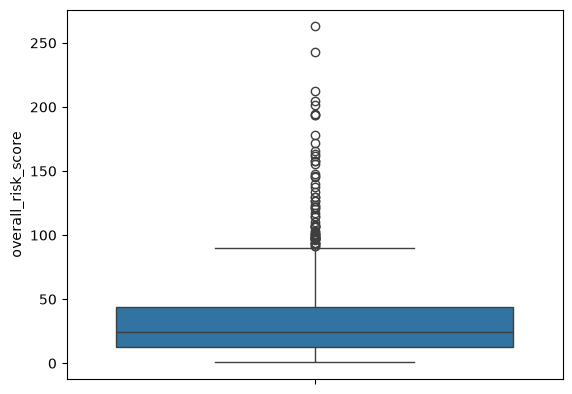

In [37]:
sns.boxplot(df['overall_risk_score'])

In [38]:
df['overall_risk_score'].skew()

np.float64(2.4417867212108373)

In [39]:
df['overall_risk_score'].nunique()

975

In [40]:
df['overall_risk_score'].duplicated().sum()

np.int64(25)

## 5.4 maturity_period_years


In [41]:
df['maturity_period_years'].unique()

array([10.77,  1.01,  6.53,  5.86,  5.34,  8.56, 12.61,  8.39,  5.46,
        6.32,  6.22,  8.5 ,  7.75,  7.97,  1.45,  6.28, 11.37,  8.63,
        4.43, 10.85,  4.01, 10.26, 11.78,  7.16,  8.51,  7.93,  7.4 ,
        1.98,  5.72, 13.29,  9.25,  8.08,  6.8 ,  6.65,  7.71,  9.77,
        8.14,  8.4 ,  3.8 , 11.71,  3.49,  7.35,  5.35,  9.74,  4.6 ,
        6.58, 10.22,  8.99, 10.48,  5.83,  8.73,  4.11,  9.09,  7.54,
        7.46, 10.04,  5.92,  3.44,  3.24,  5.05,  4.8 ,  7.17,  7.63,
        9.4 ,  2.96,  8.74,  4.27,  8.13,  6.29,  4.26,  5.51,  0.5 ,
        9.33,  7.19,  4.05,  3.92,  4.91,  4.25,  6.41,  4.14,  5.15,
        9.19,  7.98,  7.84,  2.82,  7.26,  1.18,  9.28,  2.47,  2.92,
        1.26, 15.95,  8.34,  4.38, 10.67, 12.45,  6.15,  6.84,  6.76,
        7.73,  3.77,  1.82,  3.75,  6.05,  8.36,  6.46,  5.22,  1.81,
        6.13,  3.41, 10.11,  7.48,  9.04,  5.84,  6.72,  9.18,  3.35,
        3.55,  5.88,  3.56,  5.01,  8.32,  3.94,  4.52,  3.33,  6.57,
        2.68, 10.12,

<Axes: xlabel='maturity_period_years', ylabel='Density'>

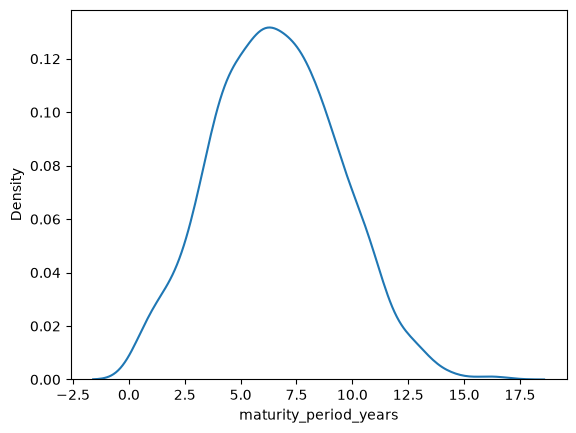

In [42]:
sns.kdeplot(df['maturity_period_years'])

<Axes: xlabel='maturity_period_years', ylabel='Density'>

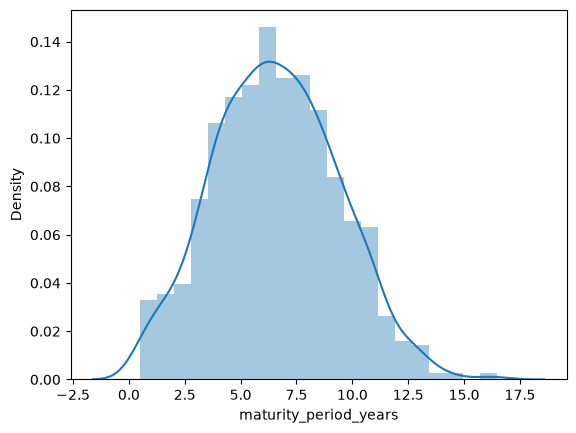

In [43]:
sns.distplot(df['maturity_period_years'])

<Axes: xlabel='maturity_period_years', ylabel='Density'>

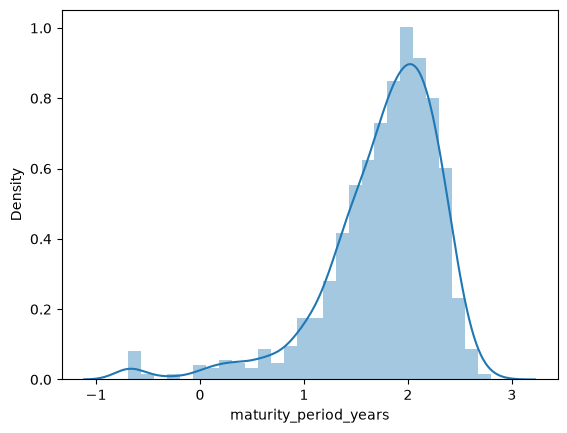

In [44]:
sns.distplot(np.log(df['maturity_period_years']))

<Axes: ylabel='maturity_period_years'>

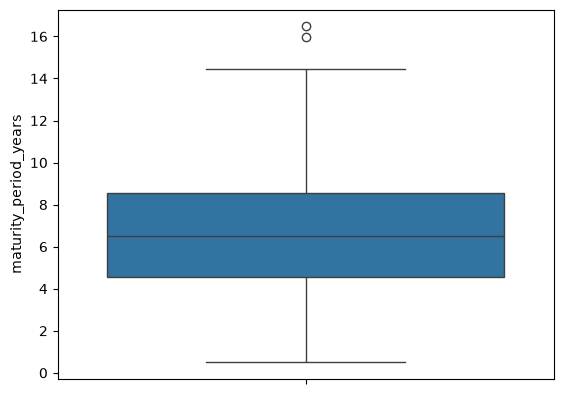

In [45]:
sns.boxplot(df['maturity_period_years'])

In [46]:
df['maturity_period_years'].skew()

np.float64(0.15557519889896784)

In [47]:
df['maturity_period_years'].nunique()

640

In [48]:
df['maturity_period_years'].duplicated().sum()

np.int64(360)

## 5.5 total_return_rate

In [49]:
df['total_return_rate'].unique()

array([ 6.665,  4.977,  5.554, 11.427,  5.093,  5.687,  7.225,  6.399,
        4.654,  4.926,  4.918,  7.211,  9.241,  2.794,  5.062,  4.487,
        3.419,  5.612,  3.407,  7.795,  6.   ,  4.642,  8.186,  7.54 ,
        5.389,  5.908,  5.187,  4.064,  2.717,  5.889,  3.488,  4.557,
        4.75 ,  4.972,  6.26 ,  2.607,  5.901,  2.114, 58.673,  5.322,
        4.606,  8.25 ,  5.02 ,  3.787,  4.872,  3.493,  5.958,  4.847,
        8.091,  7.728,  3.837,  4.611,  8.285,  5.084,  8.412,  6.019,
        2.889,  4.353,  4.008,  9.905,  6.145,  9.335,  7.346,  7.207,
        2.536,  3.906,  3.273,  6.053,  3.442,  4.705,  2.538,  3.946,
        3.699,  8.015,  4.326,  4.068,  4.953,  2.791,  2.83 ,  3.917,
        4.36 ,  5.265,  4.902,  2.873,  4.662,  5.801,  6.126,  5.252,
        2.626,  6.67 ,  3.767,  7.287,  5.718,  6.867,  4.61 ,  7.149,
        5.098,  3.804,  4.648,  4.315,  4.613,  4.799,  3.344,  3.783,
        6.301,  4.821, 11.017,  5.946,  5.953,  3.503,  4.83 ,  6.701,
      

<Axes: xlabel='total_return_rate', ylabel='Density'>

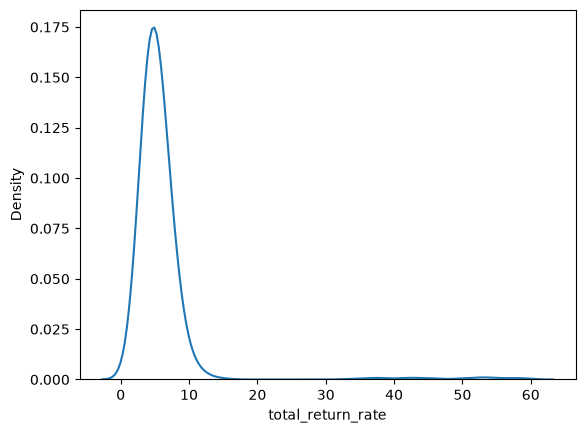

In [50]:
sns.kdeplot(df['total_return_rate'])

<Axes: xlabel='total_return_rate', ylabel='Density'>

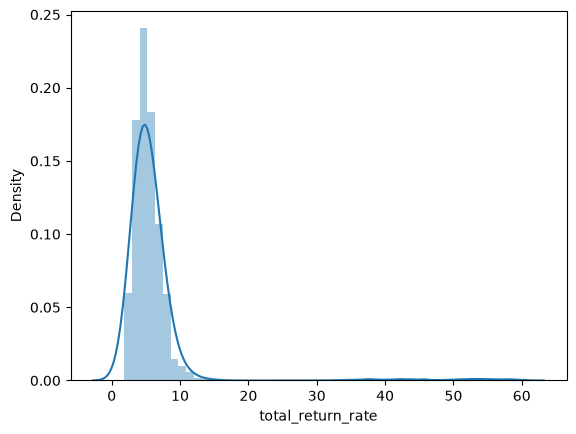

In [51]:
sns.distplot(df['total_return_rate'])

<Axes: xlabel='total_return_rate', ylabel='Density'>

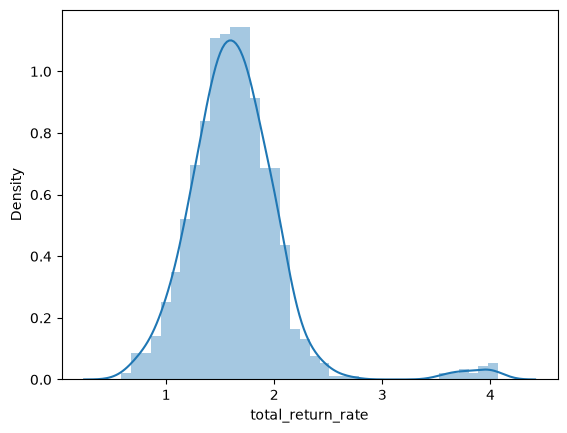

In [52]:
sns.distplot(np.log(df['total_return_rate']))

<Axes: ylabel='total_return_rate'>

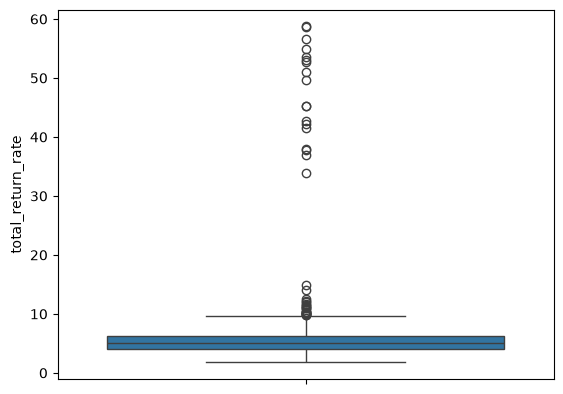

In [53]:
sns.boxplot(df['total_return_rate'])

In [54]:
df['total_return_rate'].skew()

np.float64(6.609744883825756)

In [55]:
df['total_return_rate'].nunique()

909

In [56]:
df['total_return_rate'].duplicated().sum()

np.int64(91)

## 5.6 interest_rate_trend

In [57]:
df['interest_rate_trend'].unique()

array([ 3.5610e-01, -3.0540e-01,  1.4426e+00, -2.4110e-01, -7.3710e-01,
        9.6260e-01,  6.5540e-01,  9.7600e-01, -1.4482e+00,  6.6650e-01,
        1.3272e+00,  1.1915e+00,  1.5750e-01,  5.8860e-01, -6.3910e-01,
        5.1500e-01,  1.3600e-02,  8.0870e-01, -2.6575e+00, -4.1110e-01,
        1.6820e-01,  1.4971e+00,  6.1120e-01, -9.9850e-01, -2.8960e-01,
       -1.9344e+00, -1.3455e+00,  1.1173e+00, -1.7040e+00, -1.0810e-01,
       -1.0482e+00,  6.4280e-01, -5.5730e-01, -1.5890e-01, -4.9160e-01,
        5.0520e-01,  4.5350e-01,  1.0050e+00, -7.2150e-01, -1.5053e+00,
        2.1890e-01,  1.2880e-01, -5.8980e-01, -7.2520e-01,  7.7380e-01,
        5.9620e-01, -8.9000e-01, -3.5950e-01,  5.2960e-01,  1.3625e+00,
        1.7166e+00, -1.5830e-01,  1.3470e-01,  6.5530e-01,  1.7092e+00,
       -5.8610e-01, -3.4600e-01, -8.7090e-01, -9.6010e-01,  1.0053e+00,
        1.1116e+00,  2.2710e-01,  8.2740e-01, -1.3750e+00,  8.4530e-01,
        7.6820e-01,  1.5480e+00,  8.2220e-01,  5.2600e-02, -7.48

<Axes: xlabel='interest_rate_trend', ylabel='Density'>

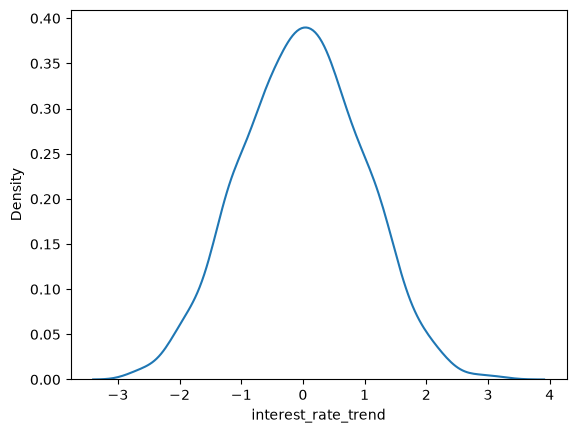

In [58]:
sns.kdeplot(df['interest_rate_trend'])

<Axes: xlabel='interest_rate_trend', ylabel='Density'>

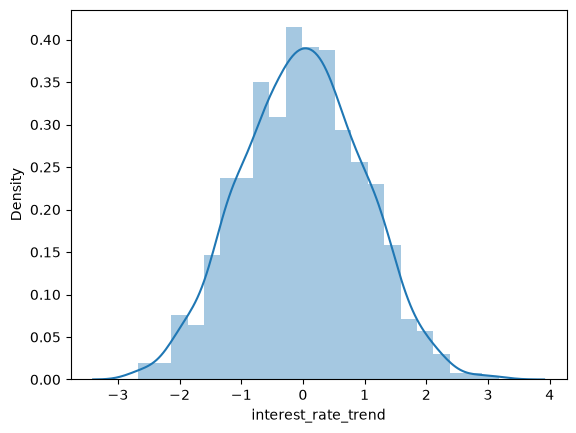

In [59]:
sns.distplot(df['interest_rate_trend'])

<Axes: xlabel='interest_rate_trend', ylabel='Density'>

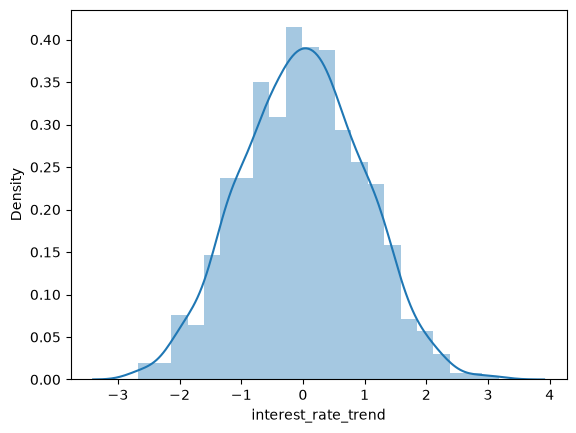

In [60]:
#sns.distplot(np.log(df['credit_rating_score'])) # you're trying to log-transform a column that isn't allowed to be logged, 
#because it has negative/zero values.
sns.distplot(df['interest_rate_trend']) 

<Axes: ylabel='interest_rate_trend'>

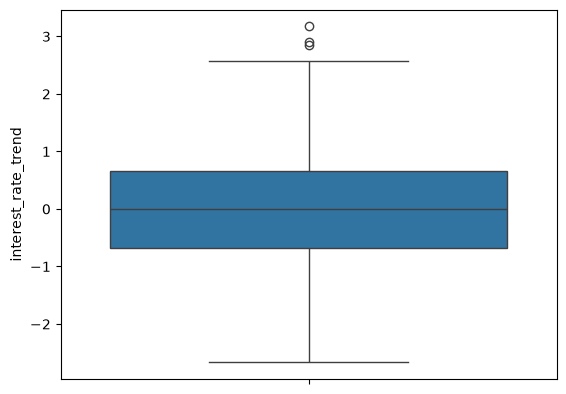

In [61]:
sns.boxplot(df['interest_rate_trend'])

In [62]:
df['interest_rate_trend'].skew()

np.float64(0.015871773287499537)

In [63]:
df['interest_rate_trend'].nunique()

989

In [64]:
df['interest_rate_trend'].duplicated().sum()

np.int64(11)

## 5.7 economic_condition_change

In [65]:
df['economic_condition_change'].unique()

array([-2.7000e-01, -1.7450e-01, -1.6980e-01, -6.1620e-01, -1.7149e+00,
        8.4280e-01,  5.5700e-02, -2.7300e-01, -5.1080e-01, -2.3950e-01,
       -9.1600e-02, -2.8500e-01,  1.0447e+00, -7.2350e-01,  6.1490e-01,
        2.3213e+00, -5.9470e-01,  1.9468e+00, -2.7980e-01,  3.2860e-01,
       -3.2450e-01,  1.2187e+00, -6.1950e-01,  8.5930e-01, -7.2460e-01,
       -8.7170e-01,  1.0506e+00,  9.0100e-02,  2.1310e-01, -1.7835e+00,
        2.2658e+00,  4.1080e-01,  1.7710e-01,  2.8310e-01,  7.3450e-01,
        3.6660e-01,  2.0612e+00,  6.1280e-01,  6.4190e-01, -1.2082e+00,
       -1.0593e+00,  5.0600e-02, -5.6340e-01, -3.6810e-01,  7.6660e-01,
       -2.2900e-01,  4.6500e-01, -8.5220e-01, -1.0010e+00,  1.5706e+00,
       -2.8660e-01, -8.8690e-01, -1.3620e-01, -1.0490e-01,  1.0574e+00,
       -1.1418e+00, -3.6000e-01, -7.6170e-01,  9.5040e-01,  9.7660e-01,
        1.3121e+00, -1.9840e-01, -1.7940e-01, -3.0180e-01,  1.3696e+00,
        1.7345e+00, -2.8840e-01, -4.1110e-01, -6.9000e-01,  1.19

<Axes: xlabel='economic_condition_change', ylabel='Density'>

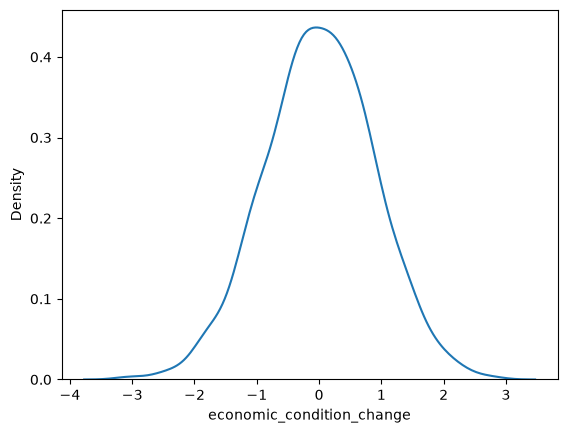

In [66]:
sns.kdeplot(df['economic_condition_change'])

<Axes: xlabel='economic_condition_change', ylabel='Density'>

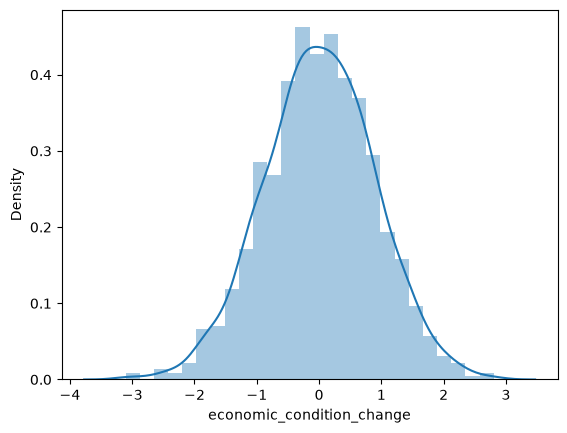

In [67]:
sns.distplot(df['economic_condition_change'])

<Axes: xlabel='economic_condition_change', ylabel='Density'>

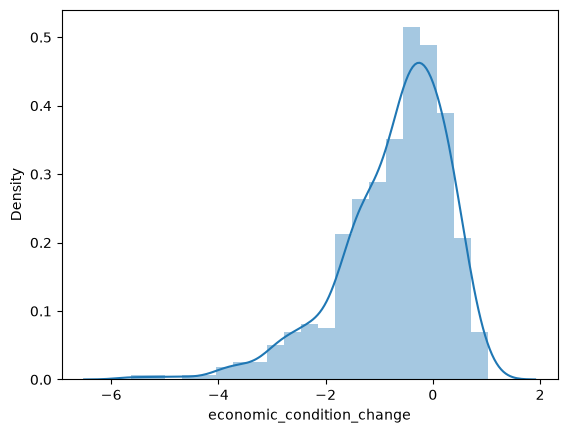

In [68]:
sns.distplot(np.log(df['economic_condition_change']))

<Axes: ylabel='economic_condition_change'>

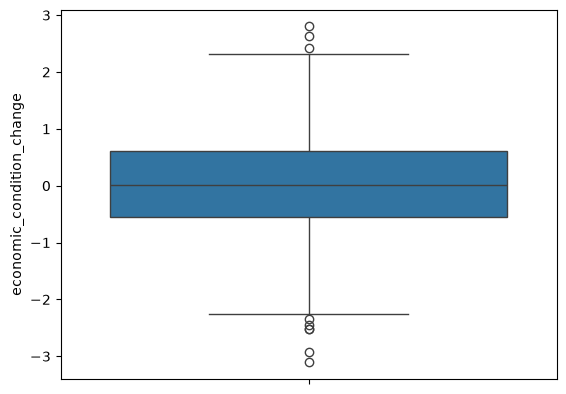

In [69]:
sns.boxplot(df['economic_condition_change'])

In [70]:
df['economic_condition_change'].skew()

np.float64(-0.06652069853177374)

In [71]:
df['economic_condition_change'].nunique()

982

In [72]:
df['economic_condition_change'].duplicated().sum()

np.int64(18)

## 5.8 market_sentiment_change

In [73]:
df['credit_rating_score'].unique()

array([13.,  9., 11., 15., 12., 10.,  5., 18.,  7., 19., 17., 14.,  8.,
        6., 21., 16.,  4., 20., 22.,  3.,  2.,  1.])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

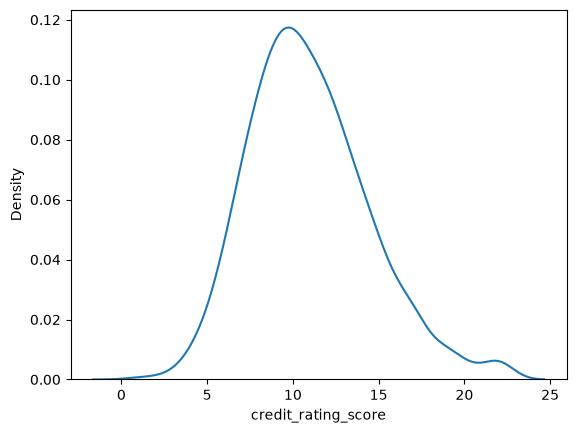

In [74]:
sns.kdeplot(df['credit_rating_score'])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

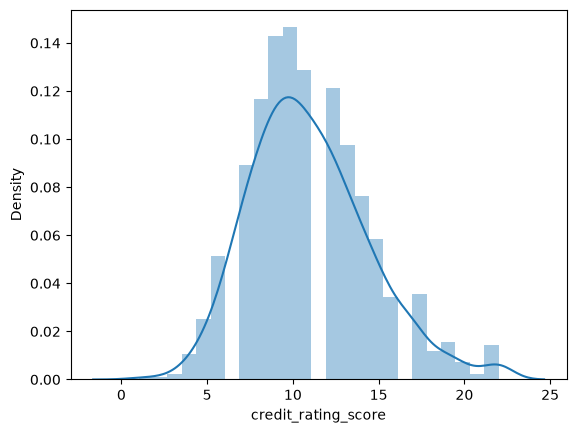

In [75]:
sns.distplot(df['credit_rating_score'])

<Axes: xlabel='credit_rating_score', ylabel='Density'>

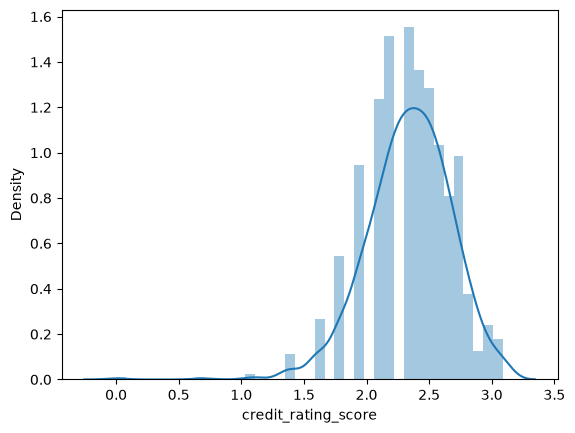

In [76]:
sns.distplot(np.log(df['credit_rating_score']))

<Axes: ylabel='credit_rating_score'>

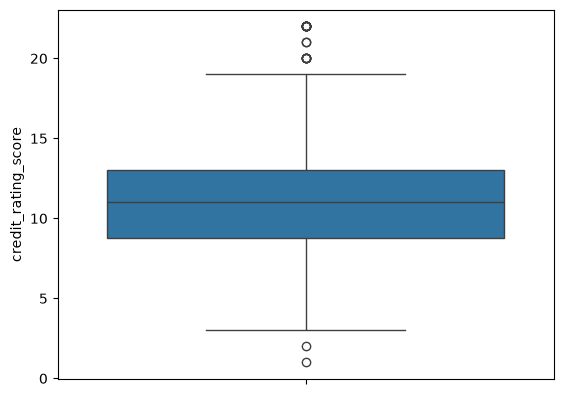

In [77]:
sns.boxplot(df['credit_rating_score'])

In [78]:
df['credit_rating_score'].skew()

np.float64(0.5847326477422036)

In [79]:
df['extra_interest_offered'].nunique()

905

In [80]:
df['extra_interest_offered'].duplicated().sum()

np.int64(95)

## 5.9 recent_performance_trend

In [81]:
df['recent_performance_trend'].unique()

array([-1.2909e+00, -1.2254e+00,  3.7700e-01,  2.7640e-01, -5.1980e-01,
        1.0527e+00,  2.0720e-01, -3.8370e-01,  1.2168e+00, -1.4900e-01,
        4.1600e-01,  1.3866e+00, -1.7700e+00,  1.3220e+00,  8.5520e-01,
        1.3713e+00, -1.4619e+00, -9.5000e-03,  2.1800e-02,  1.2580e-01,
       -4.9690e-01,  2.5135e+00, -1.4550e-01, -8.2310e-01,  4.8290e-01,
        7.3000e-03,  1.2001e+00,  2.6320e-01,  2.2940e-01, -7.8930e-01,
       -6.9820e-01,  2.3450e+00,  2.2623e+00, -1.2555e+00, -1.9044e+00,
        1.1362e+00, -1.8457e+00, -1.9056e+00, -1.0978e+00, -2.2721e+00,
        1.0280e+00,  2.1587e+00,  2.4270e-01,  1.3562e+00, -1.5463e+00,
        1.1780e+00,  1.3807e+00,  1.5732e+00, -1.1383e+00,  5.0400e-02,
        7.4910e-01,  1.7752e+00, -9.7160e-01,  1.3233e+00,  4.2680e-01,
       -1.7690e-01,  8.0200e-01,  8.4260e-01, -3.3500e-02,  3.5000e-03,
        8.6040e-01, -8.1200e-02,  8.5540e-01,  6.9680e-01, -2.6000e-02,
       -5.3940e-01,  1.8345e+00,  1.6762e+00,  5.9170e-01, -8.75

<Axes: xlabel='recent_performance_trend', ylabel='Density'>

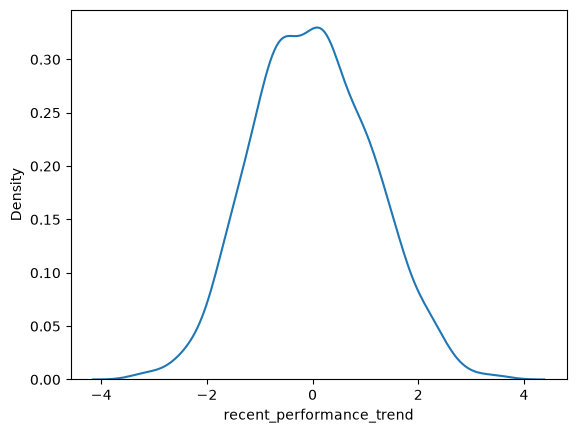

In [82]:
sns.kdeplot(df['recent_performance_trend'])

<Axes: xlabel='recent_performance_trend', ylabel='Density'>

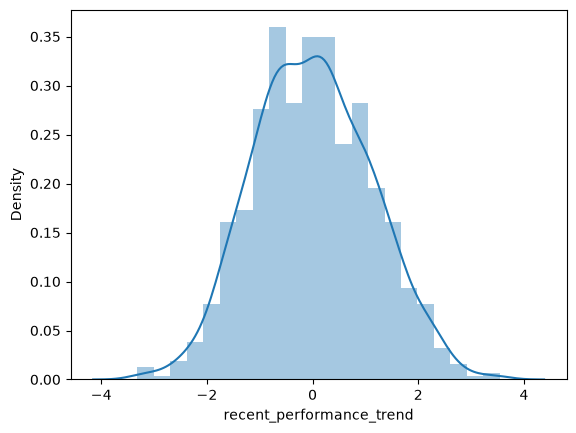

In [83]:
sns.distplot(df['recent_performance_trend'])

<Axes: xlabel='recent_performance_trend', ylabel='Density'>

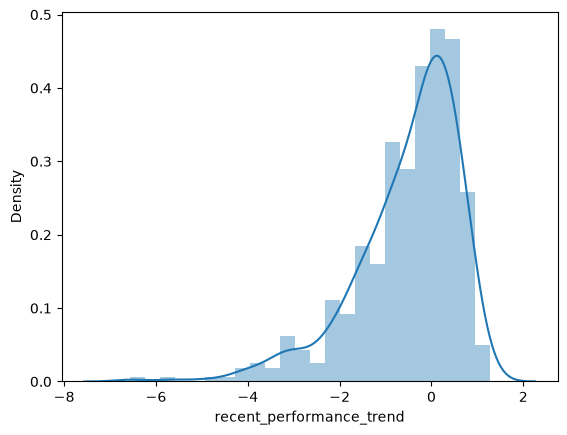

In [84]:
sns.distplot(np.log(df['recent_performance_trend']))

<Axes: ylabel='recent_performance_trend'>

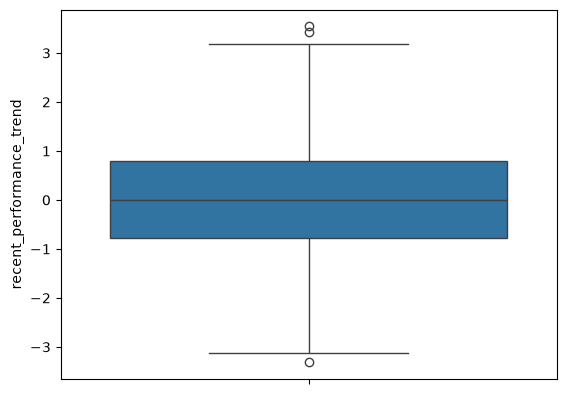

In [85]:
sns.boxplot(df['recent_performance_trend'])

In [86]:
df['recent_performance_trend'].skew()

np.float64(0.10843130754521026)

In [87]:
df['recent_performance_trend'].nunique()

979

In [88]:
df['recent_performance_trend'].duplicated().sum()

np.int64(21)

## 5.10 company_size

In [89]:
df['company_size'].unique()

array([ 9.483,  7.267,  9.367, 10.829,  7.82 ,  8.668,  8.592,  6.89 ,
        9.16 ,  8.17 ,  7.935,  7.54 ,  8.056,    nan,  9.691, 10.117,
        8.289,  7.832, 10.179,  8.676,  8.165,  7.802,  7.221,  9.618,
        9.622,  7.214,  9.532,  7.63 ,  6.447,  7.933,  6.776,  7.831,
        8.223,  7.347, 10.535, 10.434,  7.22 , 10.426,  5.091,  9.276,
        8.198,  8.059,  8.836,  6.328,  8.339,  8.774,  8.138,  8.866,
        9.434, 10.242,  8.457,  7.016,  7.728,  9.102, 10.126,  6.272,
        9.008,  5.948,  9.063,  6.571,  8.054, 10.109,  7.914,  9.749,
        7.936,  8.356,  7.294,  8.958,  6.963,  7.984,  7.901,  9.623,
        7.143, 10.408,  7.151,  8.919,  9.712,  6.586,  7.465,  8.103,
        8.868,  9.324,  9.269,  6.764,  8.605, 10.066,  7.586, 10.979,
        8.192,  6.76 ,  7.977,  7.972,  8.218,  8.277,  7.274,  7.953,
        7.96 ,  6.975,  9.022,  9.031,  6.542,  9.181,  9.366,  9.439,
       11.38 , 10.893,  6.788,  8.822,  7.208,  6.828,  8.139,  9.014,
      

<Axes: xlabel='company_size', ylabel='Density'>

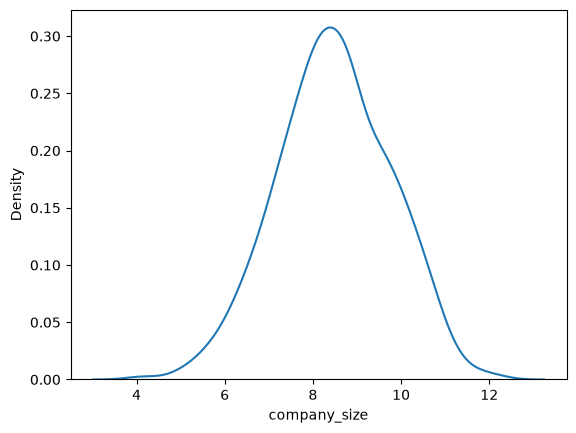

In [90]:
sns.kdeplot(df['company_size'])

<Axes: xlabel='company_size', ylabel='Density'>

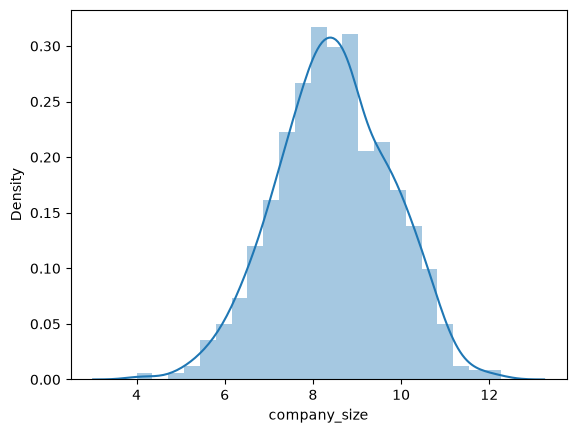

In [91]:
sns.distplot(df['company_size'])

<Axes: xlabel='company_size', ylabel='Density'>

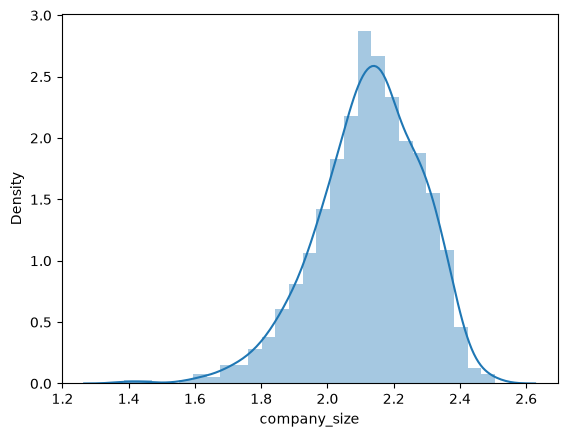

In [92]:
sns.distplot(np.log(df['company_size']))

<Axes: ylabel='company_size'>

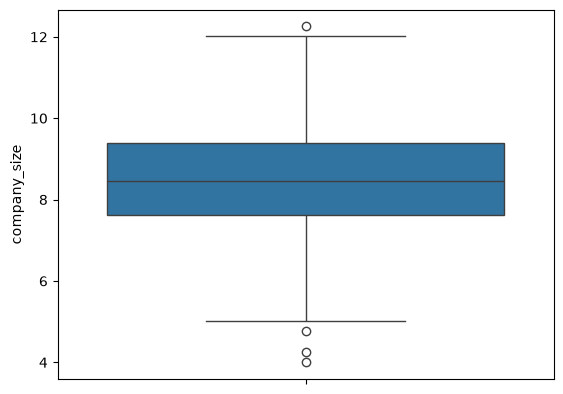

In [93]:
sns.boxplot(df['company_size'])

<Axes: ylabel='company_size'>

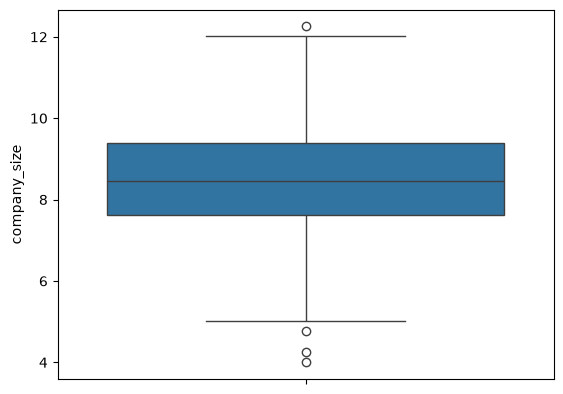

In [94]:
sns.boxplot(df['company_size'])

In [95]:
df['company_size'].skew()

np.float64(-0.08820597737384774)

In [96]:
df['company_size'].nunique()

869

In [97]:
df['company_size'].duplicated().sum()

np.int64(130)

## 5.11 market_fear_level

In [98]:
df['market_fear_level'].unique()

array([ 9.  , 20.31, 26.58, 15.74, 14.61, 23.37, 16.27, 31.85, 11.2 ,
       10.91, 14.29, 31.42, 10.03, 17.76, 20.49, 22.3 , 11.87,  9.21,
       24.6 , 13.12, 13.47, 28.4 , 12.45, 10.52, 28.12, 20.04, 25.49,
       13.57, 28.94, 19.27, 17.84, 20.1 , 26.18, 16.88,  9.79, 13.82,
       14.87, 19.58, 22.77, 15.75, 31.97, 11.96, 22.57, 22.04, 26.43,
       37.9 , 40.47, 20.81, 17.4 , 12.58, 17.2 , 23.87, 23.81, 15.68,
       15.47, 18.34, 37.84, 23.19, 11.83, 18.41,  9.64, 25.09, 14.77,
       22.25, 27.86, 12.29, 10.44, 13.71, 39.39, 22.51, 10.94, 16.7 ,
        9.33, 45.29, 23.24,  9.96, 12.22, 16.43, 38.65, 31.05, 17.74,
       19.19, 24.65, 26.11, 23.35, 17.48, 14.69, 16.44, 23.78, 17.41,
       16.41, 40.98, 16.92, 16.63, 21.88,  9.62, 14.  , 26.13, 22.89,
       10.58, 29.66, 16.48, 19.53, 21.14, 12.06, 17.57, 22.5 , 22.01,
       12.4 , 20.08, 17.03, 10.76, 25.16, 20.26, 25.57, 24.13, 10.66,
       33.22, 15.36, 13.92, 26.31, 14.9 , 11.43, 35.45, 24.5 , 18.  ,
       26.08, 22.68,

<Axes: xlabel='market_fear_level', ylabel='Density'>

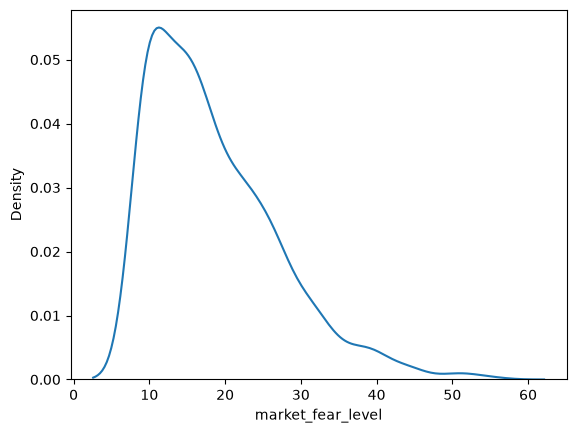

In [99]:
sns.kdeplot(df['market_fear_level'])

<Axes: xlabel='market_fear_level', ylabel='Density'>

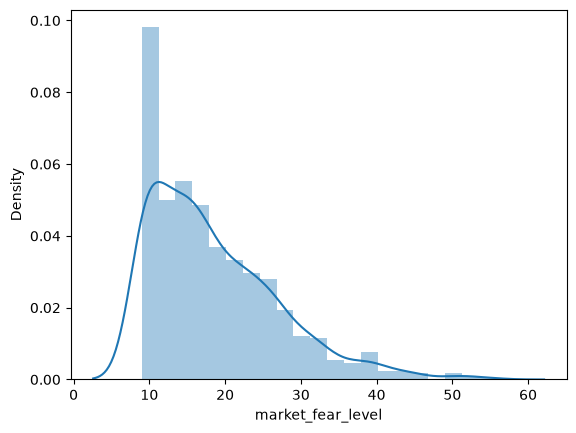

In [100]:
sns.distplot(df['market_fear_level'])

<Axes: xlabel='market_fear_level', ylabel='Density'>

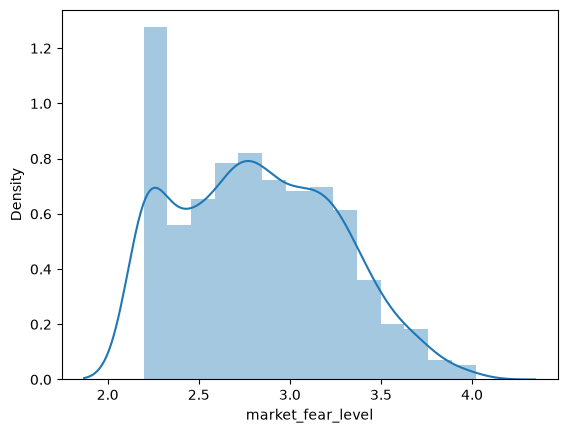

In [101]:
sns.distplot(np.log(df['market_fear_level']))

<Axes: ylabel='market_fear_level'>

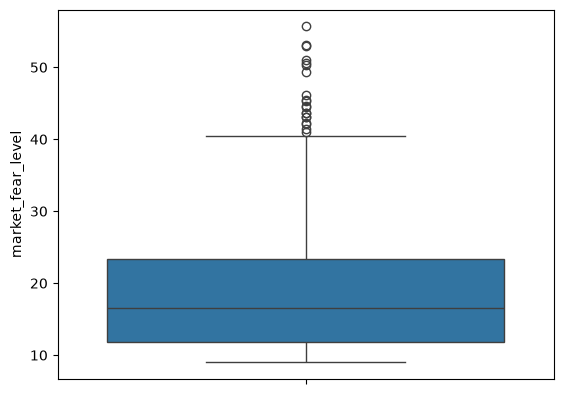

In [102]:
sns.boxplot(df['market_fear_level'])

In [103]:
df['market_fear_level'].skew()

np.float64(1.1512853282229187)

In [104]:
df['market_fear_level'].nunique()

743

In [105]:
df['market_fear_level'].duplicated().sum()

np.int64(257)

## 5.12 inflation_rate

In [106]:
df['inflation_rate'].unique()

array([ 2.9 ,  3.8 ,  4.88,  1.57,   nan,  4.51,  3.85,  2.18,  2.12,
        3.51,  1.73,  2.14,  5.13,  0.74,  1.92,  1.33,  5.77,  2.17,
       -0.27,  4.08,  2.25,  2.72,  3.55,  2.27,  3.28,  3.7 ,  2.84,
        1.69,  2.19,  4.15,  0.67,  1.12,  1.99,  2.58,  3.34,  2.7 ,
        3.39,  5.2 , -1.  ,  1.1 , -0.18,  3.72,  3.45,  3.31,  1.05,
        3.32,  1.85,  5.84,  2.22,  1.53,  3.93,  6.39,  2.88,  4.72,
        2.62,  2.45,  3.86,  3.78,  2.2 , -0.07,  1.88,  0.88,  1.35,
        1.39,  3.06, -0.04,  1.87,  4.98,  2.46,  3.73,  5.26,  1.89,
        1.84,  2.71,  4.57,  1.5 ,  2.55,  1.78,  0.73,  4.45,  2.41,
        2.36,  1.3 ,  4.07,  3.16,  1.75,  0.05,  2.15,  1.61,  4.44,
        1.97,  3.71,  3.25,  1.47,  2.48,  1.03,  2.65,  1.49,  4.56,
        5.08,  2.  ,  2.91,  2.59,  3.29,  4.24,  4.37,  5.16,  1.63,
        1.76,  3.11,  3.03,  3.77,  2.43,  3.47,  4.14,  3.61,  2.16,
        0.76, -0.2 ,  1.55,  4.93,  2.68, -0.29,  3.09,  4.18,  2.81,
        4.04,  2.97,

<Axes: xlabel='inflation_rate', ylabel='Density'>

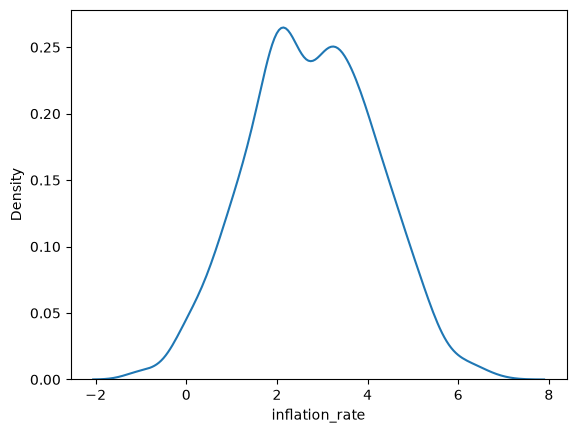

In [107]:
sns.kdeplot(df['inflation_rate'])

<Axes: xlabel='inflation_rate', ylabel='Density'>

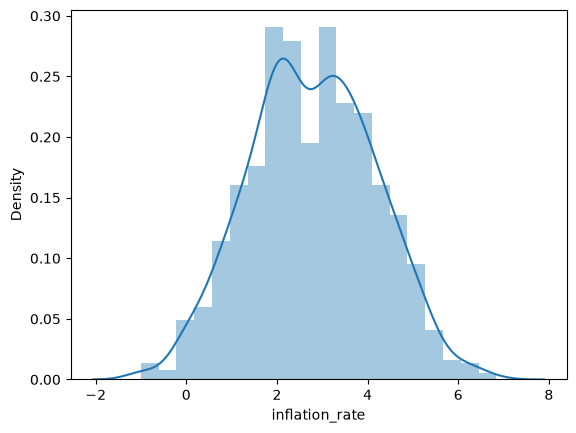

In [108]:
sns.distplot(df['inflation_rate'])

<Axes: xlabel='inflation_rate', ylabel='Density'>

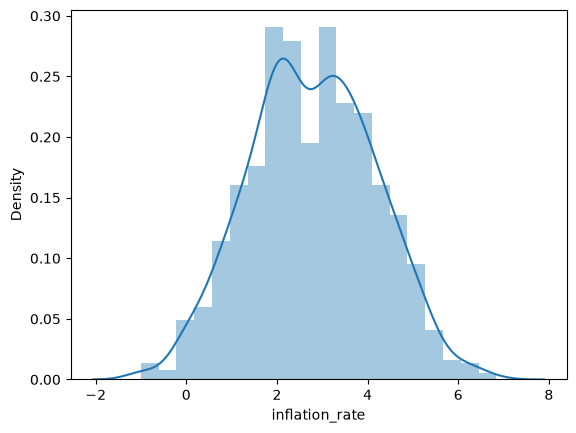

In [109]:
#sns.distplot(np.log(df['credit_rating_score'])) # you're trying to log-transform a column that isn't allowed to be logged, because it has negative/zero values.
sns.distplot(df['inflation_rate']) 

<Axes: ylabel='inflation_rate'>

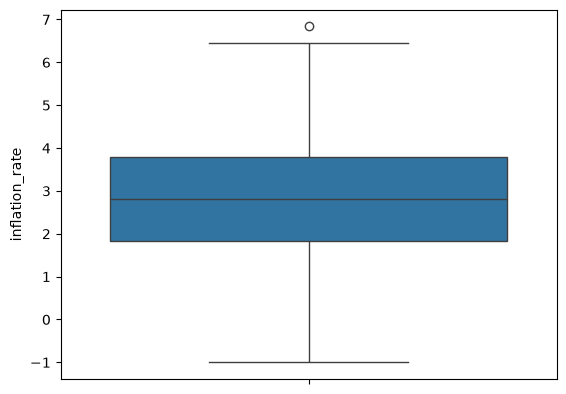

In [110]:
sns.boxplot(df['inflation_rate'])

In [111]:
df['inflation_rate'].skew()

np.float64(0.021430938375289695)

In [112]:
df['inflation_rate'].nunique()

436

In [113]:
df['inflation_rate'].duplicated().sum()

np.int64(563)

## 5.13 next_month_return_pct

In [114]:
df['next_month_return_pct'].unique()

array([-3.7630e-01, -1.4180e+00, -1.1220e-01, -1.1309e+00, -2.8150e-01,
        4.5200e-01,  2.7730e-01, -1.1394e+00, -1.7410e-01, -2.8820e-01,
       -2.2410e-01, -4.1570e-01, -1.8705e+00,  5.8000e-02, -1.4159e+00,
        1.4580e-01,  9.0200e-02, -3.1000e-01, -5.6330e-01, -1.2012e+00,
        1.9510e-01, -1.8900e-02, -1.2840e-01, -1.0720e+00,  3.6690e-01,
       -7.4820e-01,  2.2680e-01, -8.0800e-02, -1.1584e+00, -5.3480e-01,
       -2.5530e-01,  1.0351e+00,  3.6360e-01, -7.2420e-01, -1.0974e+00,
       -1.0070e-01, -5.3680e-01, -3.8920e-01, -6.0340e-01, -6.0570e-01,
        6.8080e-01,  5.8000e-01,  3.7360e-01, -7.3670e-01,  3.0500e-01,
       -1.0310e-01,  6.5510e-01, -9.3060e-01,  6.2030e-01,  8.2320e-01,
       -8.7910e-01, -1.6887e+00,  8.7240e-01,  1.2555e+00, -8.6330e-01,
       -9.8110e-01, -1.4659e+00, -7.4480e-01, -7.6100e-02,  6.9590e-01,
        4.9790e-01, -1.2506e+00, -4.8470e-01, -9.9520e-01,  9.1500e-02,
       -6.8440e-01,  2.8630e-01,  2.8610e-01,  5.6930e-01, -5.07

<Axes: xlabel='next_month_return_pct', ylabel='Density'>

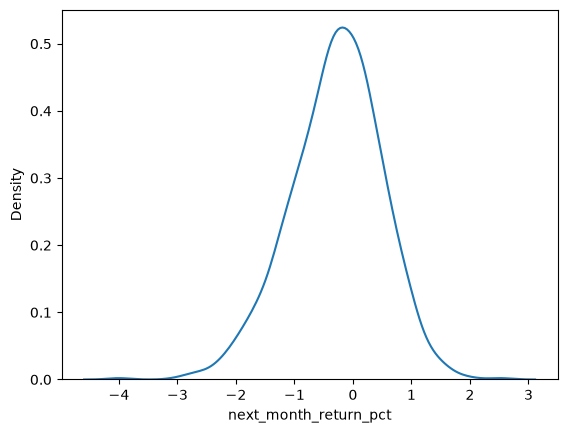

In [115]:
sns.kdeplot(df['next_month_return_pct'])

<Axes: xlabel='next_month_return_pct', ylabel='Density'>

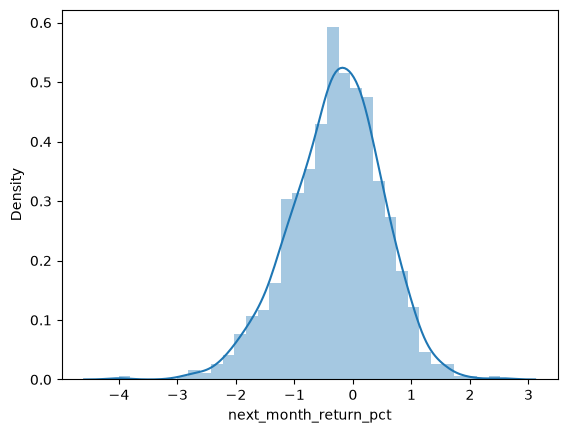

In [116]:
sns.distplot(df['next_month_return_pct'])

<Axes: xlabel='next_month_return_pct', ylabel='Density'>

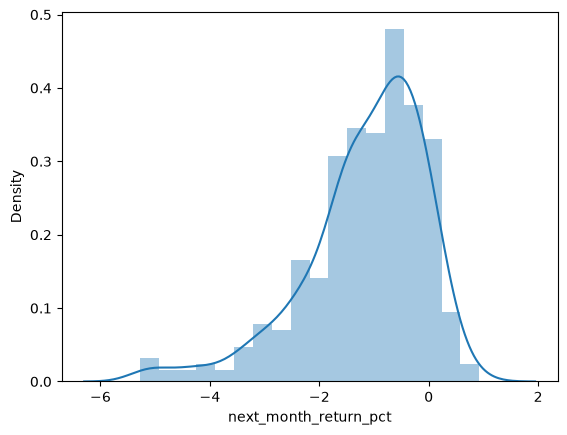

In [117]:
sns.distplot(np.log(df['next_month_return_pct']))

<Axes: ylabel='next_month_return_pct'>

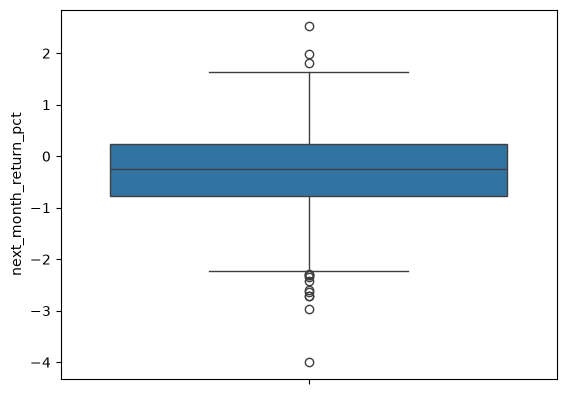

In [118]:
sns.boxplot(df['next_month_return_pct'])

In [119]:
df['next_month_return_pct'].skew()

np.float64(-0.3381613924746336)

In [120]:
df['next_month_return_pct'].nunique()

984

In [121]:
df['next_month_return_pct'].duplicated().sum()

np.int64(16)

# 6. Data Processing

In [122]:
df.drop('bond_id', axis=1, inplace=True)

In [123]:
df.head().shape

(5, 14)

In [124]:
df.describe()

,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,company_size,market_fear_level,inflation_rate,next_month_return_pct
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,950.000000,1000.000000,940.000000,1000.000000
mean,2.744075,10.963000,34.828549,6.589400,5.988134,-0.006661,0.009540,0.067291,0.004558,8.473546,18.589280,2.779457,-0.290323
std,1.646899,3.511689,33.173279,2.784796,5.977496,0.973493,0.881745,0.982344,1.110514,1.292178,8.517514,1.381796,0.784910
min,0.349000,1.000000,0.711000,0.500000,1.788000,-2.666400,-3.106600,-2.949300,-3.315100,4.000000,9.000000,-1.000000,-4.002000
25%,1.502000,8.750000,12.908250,4.557500,3.979000,-0.674850,-0.555725,-0.606750,-0.786525,7.609250,11.787500,1.840000,-0.772050
50%,2.396000,11.000000,24.376500,6.500000,4.988500,-0.000950,0.013500,0.099350,-0.009650,8.449500,16.525000,2.810000,-0.254550
75%,3.564000,13.000000,44.194500,8.532500,6.304000,0.656375,0.610775,0.736475,0.803250,9.389750,23.355000,3.782500,0.232325
max,11.951000,22.000000,262.922000,16.480000,58.759000,3.175300,2.803000,2.675600,3.544000,12.258000,55.690000,6.840000,2.521700


In [125]:
df = pd.read_csv("bond_data.csv")
print("Original shape:", df.shape)

Original shape: (1000, 15)


## 6.1 Missing Value Handling

In [126]:
print(df.isnull().sum())

bond_id                       0
obs_date                      0
extra_interest_offered        0
credit_rating_score           0
overall_risk_score            0
maturity_period_years         0
total_return_rate             0
interest_rate_trend           0
economic_condition_change     0
market_sentiment_change       0
recent_performance_trend      0
company_size                 50
market_fear_level             0
inflation_rate               60
next_month_return_pct         0
dtype: int64


In [127]:
df['company_size'].median()

np.float64(8.4495)

In [128]:
df['company_size'] = df['company_size'].fillna(df['company_size'].median())
df['company_size']

0       9.4830
1       7.2670
2       9.3670
3      10.8290
4       7.8200
        ...   
995     8.4495
996     9.4030
997    10.0450
998     8.1810
999     5.4590
Name: company_size, Length: 1000, dtype: float64

In [129]:
df['inflation_rate'].median()

np.float64(2.81)

In [130]:
df['inflation_rate'] = df['inflation_rate'].fillna(df['inflation_rate'].median())
df['inflation_rate'] 

0      2.90
1      3.80
2      4.88
3      1.57
4      2.81
       ... 
995    2.81
996    3.79
997    0.82
998    1.55
999    3.47
Name: inflation_rate, Length: 1000, dtype: float64

In [131]:
print(df.isnull().sum())

bond_id                      0
obs_date                     0
extra_interest_offered       0
credit_rating_score          0
overall_risk_score           0
maturity_period_years        0
total_return_rate            0
interest_rate_trend          0
economic_condition_change    0
market_sentiment_change      0
recent_performance_trend     0
company_size                 0
market_fear_level            0
inflation_rate               0
next_month_return_pct        0
dtype: int64


## 6.2 Handle outliers

In [132]:
Q1 = df['total_return_rate'].quantile(0.25)
Q3 = df['total_return_rate'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR


In [133]:
Q1 = df['total_return_rate'].quantile(0.25)
Q1

np.float64(3.979)

In [134]:
Q3 = df['total_return_rate'].quantile(0.75)
Q3

np.float64(6.304)

In [135]:
IQR = Q3 - Q1
IQR

np.float64(2.325)

In [136]:
upper_bound = Q3 + 1.5 * IQR
upper_bound

np.float64(9.791500000000001)

In [137]:
lower_bound = Q1 - 1.5 * IQR
lower_bound

np.float64(0.4914999999999998)

In [138]:
print(f"Upper bound: {upper_bound:.2f}, Max before capping: {df['total_return_rate'].max():.2f}")

Upper bound: 9.79, Max before capping: 58.76


In [139]:
df['total_return_rate'] = np.where(
    df['total_return_rate'] > upper_bound, upper_bound,
    np.where(df['total_return_rate'] < lower_bound, lower_bound, df['total_return_rate'])
)

In [140]:
print(f"Max after capping: {df['total_return_rate'].max():.2f}")

Max after capping: 9.79


In [141]:
print(f"Min after capping: {df['total_return_rate'].min():.2f}")

Min after capping: 1.79


In [142]:
df['inflation_rate'] = df['inflation_rate'].fillna(df['inflation_rate'].median())
df['inflation_rate'] 

0      2.90
1      3.80
2      4.88
3      1.57
4      2.81
       ... 
995    2.81
996    3.79
997    0.82
998    1.55
999    3.47
Name: inflation_rate, Length: 1000, dtype: float64

In [143]:
df.info

<bound method DataFrame.info of      bond_id    obs_date  extra_interest_offered  credit_rating_score  \
0    BND2507  01-01-2021                   2.813                 13.0   
1    BND2818  01-09-2021                   1.909                  9.0   
2    BND2452  01-07-2018                   2.991                 11.0   
3    BND2368  01-08-2018                   7.324                 15.0   
4    BND2242  01-10-2019                   2.756                 12.0   
..       ...         ...                     ...                  ...   
995  BND2767  01-11-2018                   1.499                  8.0   
996  BND2072  01-06-2021                   2.364                  9.0   
997  BND2908  01-09-2020                   1.121                  6.0   
998  BND2235  01-09-2021                   3.942                 11.0   
999  BND2037  01-09-2018                   2.209                  9.0   

     overall_risk_score  maturity_period_years  total_return_rate  \
0                36.56

In [144]:
df

,bond_id,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,company_size,market_fear_level,inflation_rate,next_month_return_pct
0,BND2507,01-01-2021,2.813,13.0,36.569,10.77,6.6650,0.3561,-0.2700,0.7939,-1.2909,9.4830,9.00,2.90,-0.3763
1,BND2818,01-09-2021,1.909,9.0,17.181,1.01,4.9770,-0.3054,-0.1745,-0.1747,-1.2254,7.2670,20.31,3.80,-1.4180
2,BND2452,01-07-2018,2.991,11.0,32.901,6.53,5.5540,1.4426,-0.1698,0.8600,0.3770,9.3670,26.58,4.88,-0.1122
3,BND2368,01-08-2018,7.324,15.0,109.860,5.86,9.7915,-0.2411,-0.6162,0.9306,0.2764,10.8290,15.74,1.57,-1.1309
4,BND2242,01-10-2019,2.756,12.0,33.072,5.34,5.0930,-0.7371,-1.7149,0.1911,-0.5198,7.8200,9.00,2.81,-0.2815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,BND2767,01-11-2018,1.499,8.0,11.992,1.18,3.4640,0.3952,0.2798,0.5498,1.8701,8.4495,17.89,2.81,-0.3672
996,BND2072,01-06-2021,2.364,9.0,21.276,8.61,4.4170,-0.6762,-1.0482,0.7971,-1.1192,9.4030,9.00,3.79,-0.3518
997,BND2908,01-09-2020,1.121,6.0,6.726,10.46,3.3650,-0.3406,0.2867,0.6854,0.8865,10.0450,17.13,0.82,0.2241
998,BND2235,01-09-2021,3.942,11.0,43.362,10.37,5.4670,-0.8407,0.8399,0.3718,0.2227,8.1810,33.74,1.55,-0.7766


### 6.3 Droping less revelent Feature

In [145]:
df.drop('company_size', axis=1, inplace=True)

In [146]:
df.drop('inflation_rate', axis=1, inplace=True)

In [147]:
df.drop('market_fear_level', axis=1, inplace=True)

In [148]:
df

,bond_id,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,next_month_return_pct
0,BND2507,01-01-2021,2.813,13.0,36.569,10.77,6.6650,0.3561,-0.2700,0.7939,-1.2909,-0.3763
1,BND2818,01-09-2021,1.909,9.0,17.181,1.01,4.9770,-0.3054,-0.1745,-0.1747,-1.2254,-1.4180
2,BND2452,01-07-2018,2.991,11.0,32.901,6.53,5.5540,1.4426,-0.1698,0.8600,0.3770,-0.1122
3,BND2368,01-08-2018,7.324,15.0,109.860,5.86,9.7915,-0.2411,-0.6162,0.9306,0.2764,-1.1309
4,BND2242,01-10-2019,2.756,12.0,33.072,5.34,5.0930,-0.7371,-1.7149,0.1911,-0.5198,-0.2815
...,...,...,...,...,...,...,...,...,...,...,...,...
995,BND2767,01-11-2018,1.499,8.0,11.992,1.18,3.4640,0.3952,0.2798,0.5498,1.8701,-0.3672
996,BND2072,01-06-2021,2.364,9.0,21.276,8.61,4.4170,-0.6762,-1.0482,0.7971,-1.1192,-0.3518
997,BND2908,01-09-2020,1.121,6.0,6.726,10.46,3.3650,-0.3406,0.2867,0.6854,0.8865,0.2241
998,BND2235,01-09-2021,3.942,11.0,43.362,10.37,5.4670,-0.8407,0.8399,0.3718,0.2227,-0.7766


In [149]:
df.head()

,bond_id,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,next_month_return_pct
0,BND2507,01-01-2021,2.813,13.0,36.569,10.77,6.6650,0.3561,-0.2700,0.7939,-1.2909,-0.3763
1,BND2818,01-09-2021,1.909,9.0,17.181,1.01,4.9770,-0.3054,-0.1745,-0.1747,-1.2254,-1.4180
2,BND2452,01-07-2018,2.991,11.0,32.901,6.53,5.5540,1.4426,-0.1698,0.8600,0.3770,-0.1122
3,BND2368,01-08-2018,7.324,15.0,109.860,5.86,9.7915,-0.2411,-0.6162,0.9306,0.2764,-1.1309
4,BND2242,01-10-2019,2.756,12.0,33.072,5.34,5.0930,-0.7371,-1.7149,0.1911,-0.5198,-0.2815


In [150]:
df.shape

(1000, 12)

In [151]:
df.drop('bond_id', axis=1, inplace=True)

In [152]:
df.shape

(1000, 11)

In [154]:
df.head()

,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,next_month_return_pct
0,01-01-2021,2.813,13.0,36.569,10.77,6.6650,0.3561,-0.2700,0.7939,-1.2909,-0.3763
1,01-09-2021,1.909,9.0,17.181,1.01,4.9770,-0.3054,-0.1745,-0.1747,-1.2254,-1.4180
2,01-07-2018,2.991,11.0,32.901,6.53,5.5540,1.4426,-0.1698,0.8600,0.3770,-0.1122
3,01-08-2018,7.324,15.0,109.860,5.86,9.7915,-0.2411,-0.6162,0.9306,0.2764,-1.1309
4,01-10-2019,2.756,12.0,33.072,5.34,5.0930,-0.7371,-1.7149,0.1911,-0.5198,-0.2815


### 7.Time Series Analysis

In [155]:
feature_cols = [ 
    'obs_date','extra_interest_offered', 'credit_rating_score', 'overall_risk_score',
    'maturity_period_years', 'total_return_rate', 'interest_rate_trend',
    'economic_condition_change', 'market_sentiment_change', 'recent_performance_trend',
    
]

In [156]:
df.head()

,obs_date,extra_interest_offered,credit_rating_score,overall_risk_score,maturity_period_years,total_return_rate,interest_rate_trend,economic_condition_change,market_sentiment_change,recent_performance_trend,next_month_return_pct
0,01-01-2021,2.813,13.0,36.569,10.77,6.6650,0.3561,-0.2700,0.7939,-1.2909,-0.3763
1,01-09-2021,1.909,9.0,17.181,1.01,4.9770,-0.3054,-0.1745,-0.1747,-1.2254,-1.4180
2,01-07-2018,2.991,11.0,32.901,6.53,5.5540,1.4426,-0.1698,0.8600,0.3770,-0.1122
3,01-08-2018,7.324,15.0,109.860,5.86,9.7915,-0.2411,-0.6162,0.9306,0.2764,-1.1309
4,01-10-2019,2.756,12.0,33.072,5.34,5.0930,-0.7371,-1.7149,0.1911,-0.5198,-0.2815


### 8: SELECT X AND y

In [157]:
X = df[feature_cols]   #independent Column
y = df['next_month_return_pct']  #Target Column
dates = df['obs_date']
print("X shape:", X.shape, "| y shape:", y.shape, "\n")

X shape: (1000, 10) | y shape: (1000,) 



### 9: TIME-BASED SPLIT (train = past, test = most recent 20%)

In [158]:
# Convert obs_date to actual datetime FIRST
df['obs_date'] = pd.to_datetime(df['obs_date'], format='%d-%m-%Y')

# THEN assign dates
dates = df['obs_date']

# Now this will work correctly
cutoff_date = dates.quantile(0.8, interpolation='nearest')
train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

x_train, y_train = X[train_mask], y[train_mask]
x_test, y_test = X[test_mask], y[test_mask]

print("Time-based split")
print(f"  Train: {x_train.shape[0]} rows ({dates[train_mask].min().date()} to {dates[train_mask].max().date()})")
print(f"  Test : {x_test.shape[0]} rows ({dates[test_mask].min().date()} to {dates[test_mask].max().date()})\n")

Time-based split
  Train: 787 rows (2016-01-01 to 2020-08-01)
  Test : 213 rows (2020-09-01 to 2021-12-01)



In [159]:
# ============================================================
# CLEAN CELL — Fixes bond_id / obs_date leaking into X (run this as ONE cell)
# ============================================================

feature_cols = [
    'extra_interest_offered', 'credit_rating_score', 'overall_risk_score',
    'maturity_period_years', 'total_return_rate', 'interest_rate_trend',
    'economic_condition_change', 'market_sentiment_change', 'recent_performance_trend'
   
]

# Rebuild X and y cleanly — ONLY numeric features, nothing else
X = df[feature_cols]
y = df['next_month_return_pct']
dates = df['obs_date']   # kept separately, only used for the time-based split

# Time-based split (train = past, test = most recent 20%)
cutoff_date = dates.quantile(0.8, interpolation='nearest')
train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

x_train, y_train = X[train_mask], y[train_mask]
x_test, y_test = X[test_mask], y[test_mask]

print(f"Train: {x_train.shape[0]} rows | Test: {x_test.shape[0]} rows")
print("x_train dtypes:\n", x_train.dtypes)

# Safety check — will raise a clear error if any non-numeric column snuck in
assert all(x_train.dtypes.apply(lambda d: d.kind in 'if')), "Non-numeric column found in x_train!"

# Scale (fit ONLY on train, apply to test)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("\n Features scaled successfully — x_train_scaled shape:", x_train_scaled.shape)

Train: 787 rows | Test: 213 rows
x_train dtypes:
 extra_interest_offered       float64
credit_rating_score          float64
overall_risk_score           float64
maturity_period_years        float64
total_return_rate            float64
interest_rate_trend          float64
economic_condition_change    float64
market_sentiment_change      float64
recent_performance_trend     float64
dtype: object

 Features scaled successfully — x_train_scaled shape: (787, 9)


In [160]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print("Features scaled using StandardScaler (fit on train only)\n")

Features scaled using StandardScaler (fit on train only)



### 10: HYPERPARAMETER TUNING (TimeSeriesSplit)

In [161]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import Lasso

print("Tuning Lasso's alpha using TimeSeriesSplit cross-validation")

tscv = TimeSeriesSplit(n_splits=5)
param_grid = {'alpha': [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]}

lasso_cv = GridSearchCV(
    Lasso(max_iter=5000),
    param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1
)
lasso_cv.fit(x_train_scaled, y_train)

best_alpha = lasso_cv.best_params_['alpha']
print(f"  Best alpha: {best_alpha}")
print(f"  Best CV R2 (time-series folds): {lasso_cv.best_score_:.4f}\n")

Tuning Lasso's alpha using TimeSeriesSplit cross-validation
  Best alpha: 0.0005
  Best CV R2 (time-series folds): 0.6981



### 11: TRAIN FINAL MODEL 

In [162]:
final_model = Lasso(alpha=best_alpha, max_iter=5000)
final_model.fit(x_train_scaled, y_train)
print("Final Lasso model trained with best alpha.\n")

Final Lasso model trained with best alpha.



### 12: PREDICT

In [163]:
y_train_pred = final_model.predict(x_train_scaled)
y_test_pred = final_model.predict(x_test_scaled)
print("Predictions generated for train and test sets.\n")

Predictions generated for train and test sets.



## 13: Evaluation 

In [164]:
def print_metrics(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"---- {name} METRICS ----")
    print(f"  MAE  : {mae:.4f}")
    print(f"  MSE  : {mse:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R2   : {r2:.4f}\n")
    return r2
 
print("STEP 11: Evaluation")
train_r2 = print_metrics("TRAINING", y_train, y_train_pred)
test_r2 = print_metrics("TESTING", y_test, y_test_pred)
 
print(f"Train-Test R2 Gap: {train_r2 - test_r2:.4f} (small gap = good generalization)\n")

STEP 11: Evaluation
---- TRAINING METRICS ----
  MAE  : 0.3403
  MSE  : 0.1834
  RMSE : 0.4282
  R2   : 0.7038

---- TESTING METRICS ----
  MAE  : 0.3397
  MSE  : 0.1839
  RMSE : 0.4289
  R2   : 0.6946

Train-Test R2 Gap: 0.0092 (small gap = good generalization)



### 14: FEATURE IMPORTANCE (Lasso coefficients)

In [166]:
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': final_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)
 
print("Feature Coefficients (sorted by impact)")
print(coef_df.to_string(index=False))
 
eliminated = coef_df[coef_df['Coefficient'] == 0]
if len(eliminated) > 0:
    print("\nFeatures eliminated by Lasso (coefficient = 0):", eliminated['Feature'].tolist())
else:
    print("\nNo features were fully eliminated by Lasso at this alpha.")

Feature Coefficients (sorted by impact)
                  Feature  Coefficient
       overall_risk_score    -0.558210
      interest_rate_trend     0.326854
  market_sentiment_change    -0.301575
economic_condition_change    -0.179893
   extra_interest_offered     0.151966
 recent_performance_trend     0.107471
    maturity_period_years     0.043539
        total_return_rate    -0.033468
      credit_rating_score    -0.004720

No features were fully eliminated by Lasso at this alpha.
